# Block 2 Checkpoint: Engine Demo

Name: Aidan Siddiqi
Date: 10/22/2026
Lab: PHYS 311 Block 2 Checkpoint

This notebook runs a multi-body scene on my Lab 7 physics engine, lab07_engine. The scene is two diatomic molecules colliding in free space. The engine is unchanged from Lab 7. Everything below uses only engine calls, including add_body, add_force, add_collider, watch, and run.

**AI use disclaimer:** AI (Claude) was used in preparing this notebook for coding assistance, tidying up code, and improving code flow/organization. This is not to say that there was no human work done in this code; all lines included input and assistance from myself and many iterations and human attempts are consolidated into the notebook seen below. The scene design, the figures, and the write-up for this checkpoint were also prepared with Claude's help. The engine itself is my Lab 7 submission.

In [28]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

try:
    import lab07_engine
except ModuleNotFoundError:
    for path in ("../labs/lab07", "../../labs/lab07"):
        sys.path.insert(0, path)

from lab07_engine import Body, World, Force, Spring, NewtonGravity, Drag
from lab07_engine import VelocityVerlet, CircleCollisions

os.makedirs("figures", exist_ok=True)

## Setting The Scene

Each molecule is two atoms joined by a spring, like the HCl bond I used from the Block 1 checkpoint. The two molecules start on a collision course and hit off-center, so the collision makes them rotate and vibrate. There is a weak attraction between all atoms. There are no walls, no gravity, and no outside forces, so the system is isolated.

| Checkpoint Requirement | How Requirements are Met |
|---|---|
| At least 4 interacting bodies | 4 atoms, A1, A2, B1, B2. Every atom interacts with every other atom |
| At least 2 distinct forces | Spring (the two bonds) and NewtonGravity (a weak attraction between all atoms, standing in for an intermolecular force). One run adds Drag. A new force is added in the last section |
| At least 1 collision interaction | CircleCollisions between atoms, 4 collisions in the elastic run |
| Conservation-law validation panel | Energy, momentum, and angular momentum in three runs, in Figure 3 |
| Runs entirely on the engine | No hand-written physics loops |
| README in checkpoints/ | README.md |
| Walkthrough | Figures 1 to 4, saved as figures/ |

How the scene fits the four engine components:

```
World
  |-- bodies:      A1, A2, B1, B2           (mass 1, radius 0.4)
  |-- forces:      Spring(A1, A2)           bond, k = 40, rest length 1.4
  |                Spring(B1, B2)           bond, k = 40, rest length 1.4
  |                NewtonGravity(G = 0.5)   weak attraction between all atoms
  |-- colliders:   CircleCollisions(e)      atoms bounce off each other
  |-- integrator:  VelocityVerlet           symplectic, so energy stays bounded
```

In [29]:
def angular_momentum_about_cm(world):
    M = sum(b.m for b in world.bodies)
    R = sum(b.m * b.r for b in world.bodies) / M
    V = world.momentum() / M
    total = 0.0
    for b in world.bodies:
        r, v = b.r - R, b.v - V
        total += b.m * (r[0] * v[1] - r[1] * v[0])
    return total

def build_scene(e=1.0, drag=0.0):
    world = World(VelocityVerlet())
    a1 = world.add_body(Body(mass=1.0, pos=(-4.7, 0.0), vel=(3.0, 0.0), radius=0.4, name='A1'))
    a2 = world.add_body(Body(mass=1.0, pos=(-3.3, 0.0), vel=(3.0, 0.0), radius=0.4, name='A2'))
    b1 = world.add_body(Body(mass=1.0, pos=(4.0, -0.5), vel=(-1.0, 0.0), radius=0.4, name='B1'))
    b2 = world.add_body(Body(mass=1.0, pos=(4.0, 0.9), vel=(-1.0, 0.0), radius=0.4, name='B2'))

    bond_a = world.add_force(Spring(a1, a2, k=40.0, rest=1.4))
    bond_b = world.add_force(Spring(b1, b2, k=40.0, rest=1.4))
    pull = world.add_force(NewtonGravity(G=0.5))
    if drag > 0:
        world.add_force(Drag(drag, quadratic=False))

    pairs = world.add_collider(CircleCollisions(e=e))

    world.watch_conserved()
    world.watch_positions()
    world.watch('KE', lambda w: w.kinetic_energy())
    world.watch('PE_bonds', lambda w: bond_a.potential_energy(w) + bond_b.potential_energy(w))
    world.watch('PE_pull', lambda w: pull.potential_energy(w))
    world.watch('L_cm', angular_momentum_about_cm)
    world.watch('collisions', lambda w: pairs.count)
    return world

def describe(world):
    print("Bodies:    ", [b.name for b in world.bodies])
    print("Forces:    ", [type(f).__name__ for f in world.forces])
    print("Colliders: ", [type(c).__name__ for c in world.colliders])
    print("Integrator:", type(world.integrator).__name__)

The next cell builds the baseline run, an elastic collision (e = 1), and prints what the World contains. The custom watcher L_cm is the angular momentum about the center of mass.

In [30]:
dt = 0.0005

world = build_scene()
describe(world)
data = world.run(dt, t_end=8.0, record_every=10)

t = data['t']
hit_times = t[np.where(np.diff(data['collisions']) > 0)[0] + 1]

print()
print(f"Steps: {int(8.0 / dt)}, recorded points: {len(t)}")
print(f"Atom-atom collisions: {int(data['collisions'][-1])}")
print("Collision times (s):", np.round(hit_times, 3))
print(f"Total momentum at the start: ({data['px'][0]:.3f}, {data['py'][0]:.3f})")

Bodies:     ['A1', 'A2', 'B1', 'B2']
Forces:     ['Spring', 'Spring', 'NewtonGravity']
Colliders:  ['CircleCollisions']
Integrator: VelocityVerlet

Steps: 16000, recorded points: 1601
Atom-atom collisions: 4
Collision times (s): [1.64  1.74  2.045 2.07 ]
Total momentum at the start: (4.000, 0.000)


## Walkthrough

### Figure 1: Collision

There are eight snapshots, with panels 3, 4 and 5 taken at three of the four collisions. Thin lines are the paths of the atoms. Blue is molecule A and orange is molecule B. The black line is the bond.

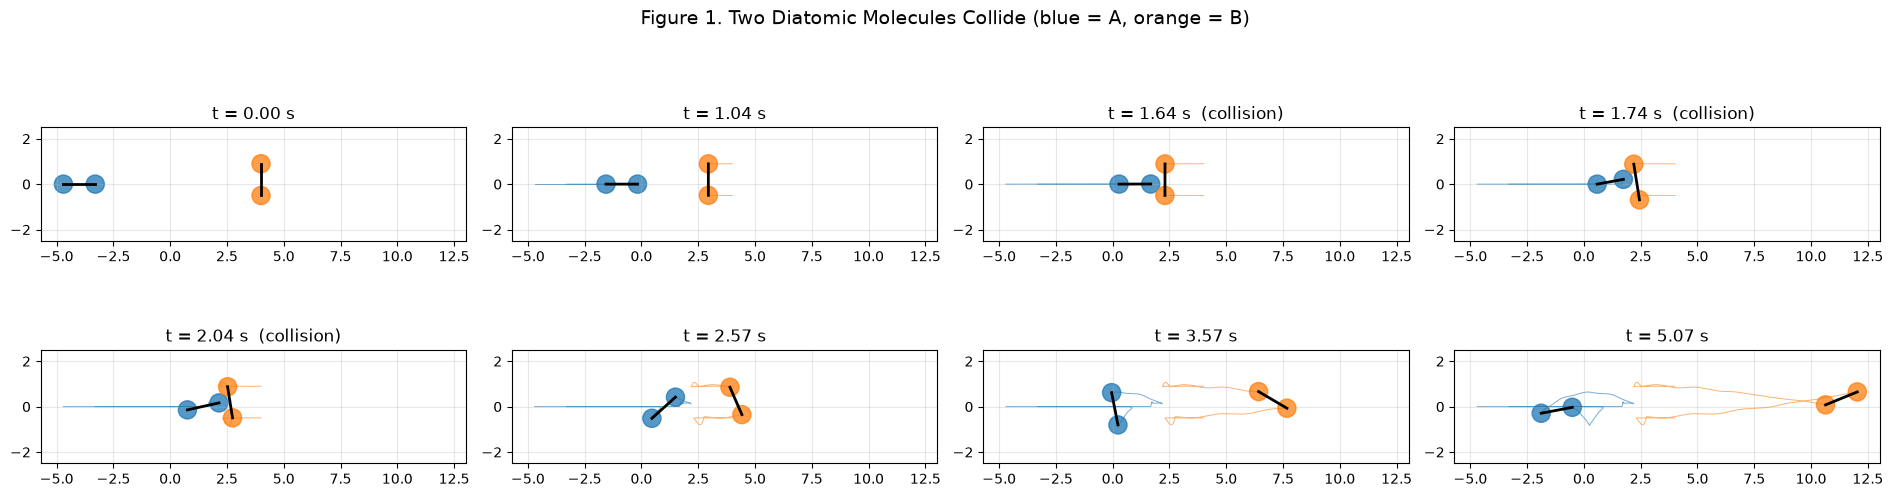

In [22]:
names = ['A1', 'A2', 'B1', 'B2']
colors = {'A': 'tab:blue', 'B': 'tab:orange'}
snap_times = [0.0, hit_times[0] - 0.6, hit_times[0], hit_times[1],
              hit_times[2], hit_times[3] + 0.5, hit_times[3] + 1.5, hit_times[3] + 3.0]

last = int(np.argmin(np.abs(t - snap_times[-1])))
x_all = np.concatenate([data[n + '.x'][:last + 1] for n in names])
y_all = np.concatenate([data[n + '.y'][:last + 1] for n in names])
y_lim = max(np.abs(y_all).max() + 1.0, 2.5)

fig, axes = plt.subplots(2, 4, figsize=(19, 5.6))
for ax, ts in zip(axes.ravel(), snap_times):
    i = int(np.argmin(np.abs(t - ts)))
    for name in names:
        ax.plot(data[name + '.x'][:i + 1], data[name + '.y'][:i + 1], lw=0.7, alpha=0.6, color=colors[name[0]])
    for a, b in (('A1', 'A2'), ('B1', 'B2')):
        ax.plot([data[a + '.x'][i], data[b + '.x'][i]], [data[a + '.y'][i], data[b + '.y'][i]], 'k-', lw=2)
    for name in names:
        ax.add_patch(plt.Circle((data[name + '.x'][i], data[name + '.y'][i]), 0.4, color=colors[name[0]], alpha=0.75))
    ax.set_xlim(x_all.min() - 1, x_all.max() + 1)
    ax.set_ylim(-y_lim, y_lim)
    ax.set_aspect('equal')
    at_hit = np.min(np.abs(hit_times - t[i])) < 0.006
    ax.set_title(f"t = {t[i]:.2f} s" + ("  (collision)" if at_hit else ""))
    ax.grid(alpha=0.3)

fig.suptitle("Figure 1. Two Diatomic Molecules Collide (blue = A, orange = B)", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig1_collision_sequence.png", dpi=110)
plt.show()

Molecule A comes in from the left. Its right atom hits the lower atom of molecule B, then the upper atom 0.1 s later, then both again about 0.3 s after that. The hits are off-center, so both molecules leave spinning and vibrating. Figure 2 shows the vibration as energy.

### Figure 2: What Happens to the Energy

The left panel splits the total energy into kinetic energy and the two potential energies; the right panel zooms in on the error in the total.

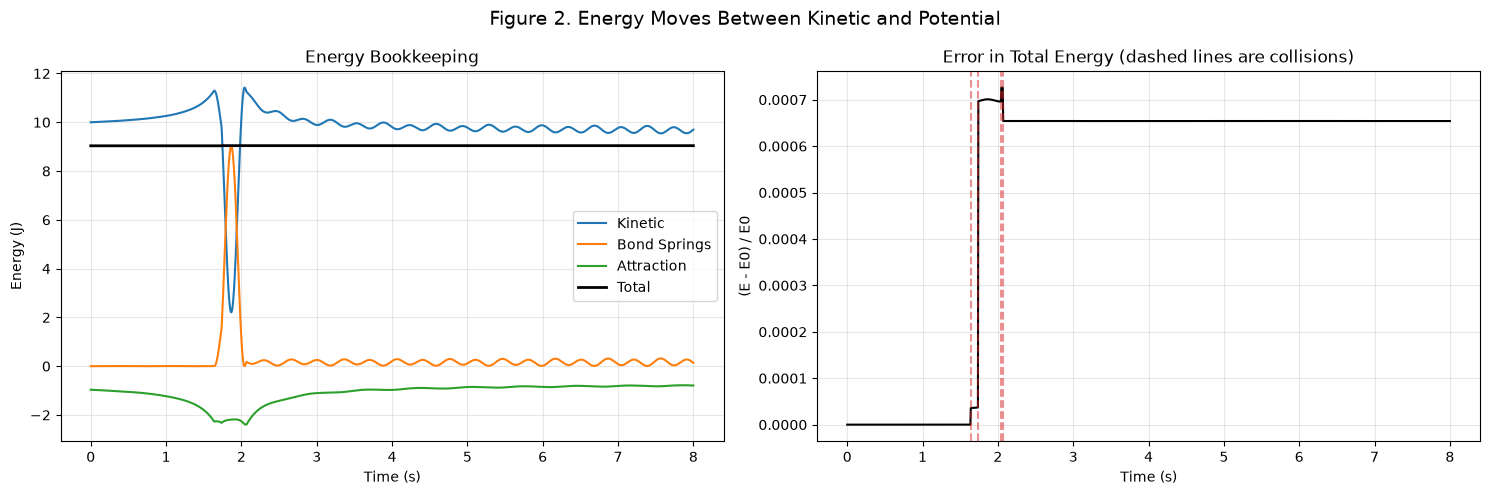

Largest |E - E0| / E0 over the run: 7.26e-04


In [23]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].plot(t, data['KE'], label='Kinetic')
ax[0].plot(t, data['PE_bonds'], label='Bond Springs')
ax[0].plot(t, data['PE_pull'], label='Attraction')
ax[0].plot(t, data['E'], 'k', linewidth=2, label='Total')
ax[0].set_xlabel('Time (s)')
ax[0].set_ylabel('Energy (J)')
ax[0].set_title('Energy Bookkeeping')
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].plot(t, (data['E'] - data['E'][0]) / data['E'][0], color='black')
for th in hit_times:
    ax[1].axvline(th, color='tab:red', linestyle='--', alpha=0.5)
ax[1].set_xlabel('Time (s)')
ax[1].set_ylabel('(E - E0) / E0')
ax[1].set_title('Error in Total Energy (dashed lines are collisions)')
ax[1].grid(alpha=0.3)

fig.suptitle("Figure 2. Energy Moves Between Kinetic and Potential", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig2_energy_bookkeeping.png", dpi=110)
plt.show()

print(f"Largest |E - E0| / E0 over the run: {np.max(np.abs(data['E'] - data['E'][0])) / data['E'][0]:.2e}")

Kinetic energy turns into bond energy at the collision, and the bonds then keep vibrating. The total stays flat. Its error is small. The error appears to moves in small steps right at the collisions, noted with th dashed lines.

## Conservation-Law Validation

The same scene runs three ways. Each one should behave differently, and each difference has a physical reason.

| Run | What changes | What should happen |
|---|---|---|
| A. Elastic (e = 1) | nothing | Energy, momentum, and angular momentum are all conserved |
| B. Inelastic (e = 0.8) | atoms lose energy when they collide | Energy drops, only at collisions. Momentum and angular momentum are conserved |
| C. Elastic with Drag | a drag force acts on every atom | Energy falls smoothly. Momentum and angular momentum are not conserved, since drag is an outside force |

The collision impulse only pushes along the line between two atoms, so it cannot change total momentum or angular momentum. That is why run B is a good test.

In [24]:
runs = {'A. Elastic (e = 1)': data}
runs['B. Inelastic (e = 0.8)'] = build_scene(e=0.8).run(dt, t_end=8.0, record_every=10)
runs['C. Elastic + drag'] = build_scene(drag=0.1).run(dt, t_end=8.0, record_every=10)

def momentum_error(d):
    return np.hypot(d['px'] - d['px'][0], d['py'] - d['py'][0])

print(f"{'Run':<26}{'E_end / E0':<13}{'largest rise (J)':<18}{'max |dp|':<12}{'L_cm end / start'}")
for name, d in runs.items():
    E = d['E']
    rise = max(np.diff(E).max(), 0.0)
    print(f"{name:<26}{E[-1] / E[0]:<13.4f}{rise:<18.1e}{momentum_error(d).max():<12.1e}{d['L_cm'][-1] / d['L_cm'][0]:.6f}")

Run                       E_end / E0   largest rise (J)  max |dp|    L_cm end / start
A. Elastic (e = 1)        1.0007       6.0e-03           3.6e-14     1.000558
B. Inelastic (e = 0.8)    0.5070       1.6e-06           2.3e-14     1.000004
C. Elastic + drag         0.1299       0.0e+00           2.2e+00     0.447597


In [25]:
sweep_dts = [0.002, 0.001, 0.0005, 0.00025]
sweep_err = []
for d_t in sweep_dts:
    d = build_scene().run(d_t, t_end=8.0, record_every=int(round(0.005 / d_t)))
    sweep_err.append(np.max(np.abs(d['E'] - d['E'][0])) / abs(d['E'][0]))
    print(f"dt = {d_t:<8} max |dE| / E0 = {sweep_err[-1]:.2e}")

dt = 0.002    max |dE| / E0 = 3.85e-03
dt = 0.001    max |dE| / E0 = 7.76e-04
dt = 0.0005   max |dE| / E0 = 7.26e-04
dt = 0.00025  max |dE| / E0 = 1.20e-04


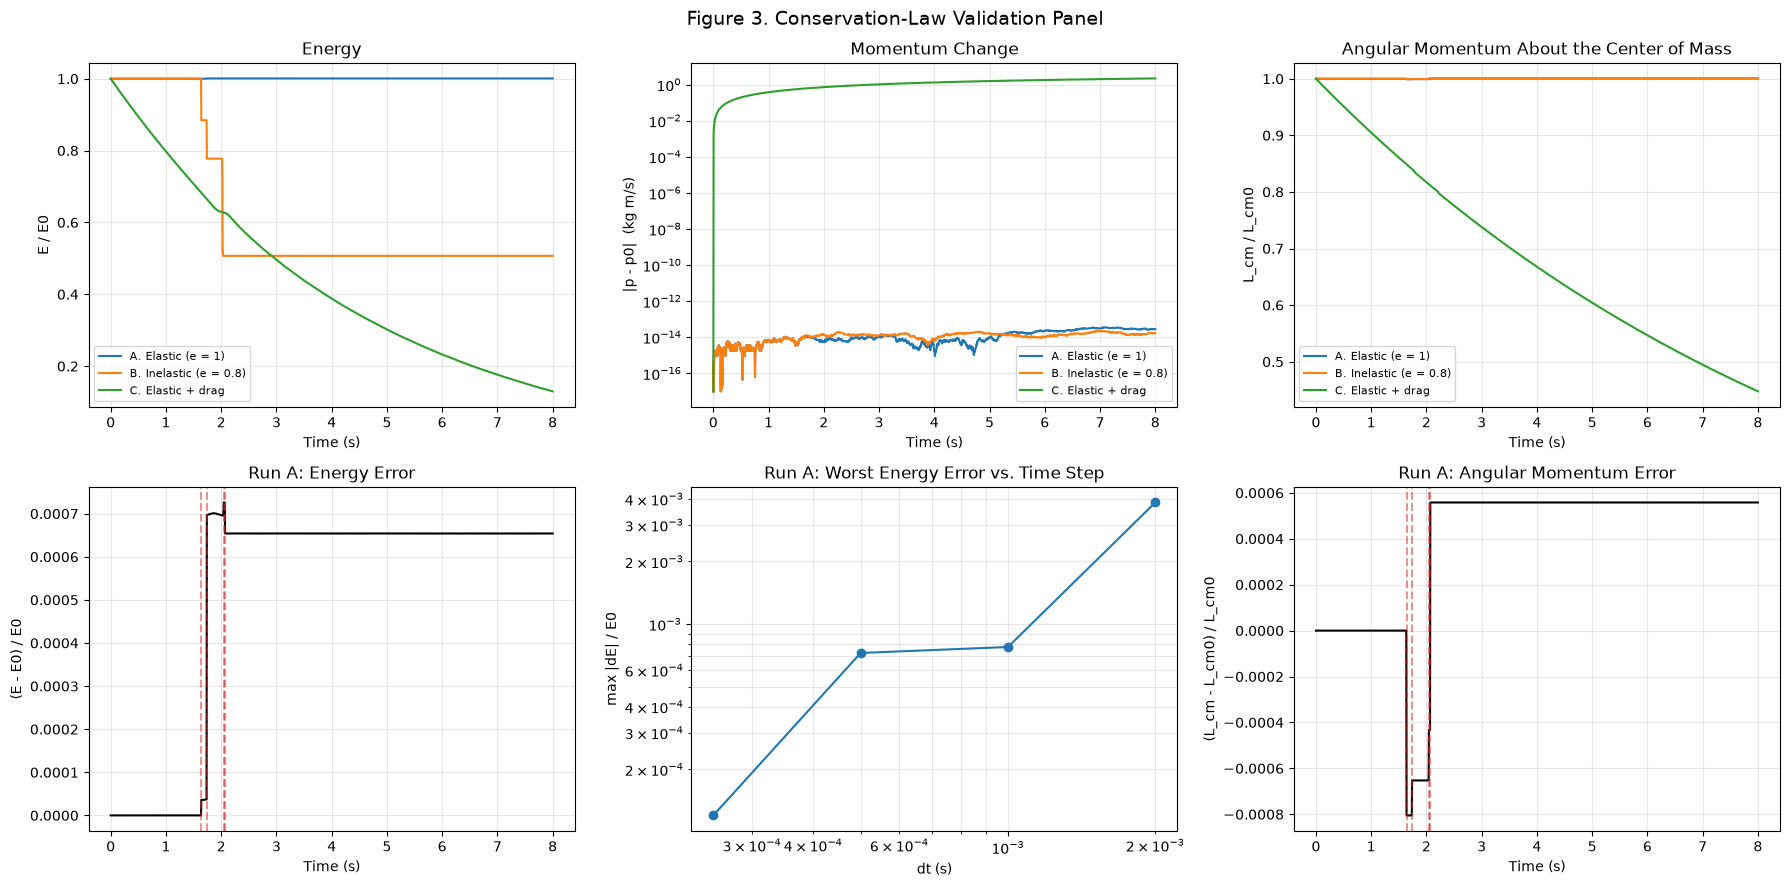

In [26]:
fig, ax = plt.subplots(2, 3, figsize=(18, 9))

for name, d in runs.items():
    ax[0, 0].plot(d['t'], d['E'] / d['E'][0], label=name)
    ax[0, 1].semilogy(d['t'], momentum_error(d) + 1e-17, label=name)
    ax[0, 2].plot(d['t'], d['L_cm'] / d['L_cm'][0], label=name)

ax[0, 0].set_title('Energy')
ax[0, 0].set_ylabel('E / E0')
ax[0, 1].set_title('Momentum Change')
ax[0, 1].set_ylabel('|p - p0|  (kg m/s)')
ax[0, 2].set_title('Angular Momentum About the Center of Mass')
ax[0, 2].set_ylabel('L_cm / L_cm0')
for a in ax[0]:
    a.set_xlabel('Time (s)')
    a.legend(fontsize=8)
    a.grid(alpha=0.3)

ax[1, 0].plot(t, (data['E'] - data['E'][0]) / data['E'][0], color='black')
ax[1, 0].set_title('Run A: Energy Error')
ax[1, 0].set_ylabel('(E - E0) / E0')

ax[1, 1].loglog(sweep_dts, sweep_err, 'o-')
ax[1, 1].set_title('Run A: Worst Energy Error vs. Time Step')
ax[1, 1].set_xlabel('dt (s)')
ax[1, 1].set_ylabel('max |dE| / E0')
ax[1, 1].grid(alpha=0.3, which='both')

ax[1, 2].plot(t, (data['L_cm'] - data['L_cm'][0]) / data['L_cm'][0], color='black')
ax[1, 2].set_title('Run A: Angular Momentum Error')
ax[1, 2].set_ylabel('(L_cm - L_cm0) / L_cm0')

for a in (ax[1, 0], ax[1, 2]):
    a.set_xlabel('Time (s)')
    for th in hit_times:
        a.axvline(th, color='tab:red', linestyle='--', alpha=0.5)
    a.grid(alpha=0.3)

fig.suptitle("Figure 3. Conservation-Law Validation Panel", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig3_validation_panel.png", dpi=110)
plt.show()

**Figure 3 summary**

| Run | Energy | Momentum | Angular momentum (about the center of mass) |
|---|---|---|---|
| A. Elastic | Conserved. The worst error is 0.07 percent of E0 | Conserved to 2e-14 kg m/s | Conserved to within 0.08 percent |
| B. Inelastic | Falls to 0.51 of E0, only in steps at collisions | Conserved to 3e-14 kg m/s | Conserved to within 0.08 percent |
| C. Elastic + drag | Falls smoothly to 0.13 of E0 | Not conserved. It changes by up to 2.2 kg m/s | Not conserved. It falls to 0.45 of its start |

Each law holds where it should and fails only where something outside the system is acting.

The error in run A is not exactly zero. It likely comes from the engine's collision handling. When two atoms overlap after a step, the engine pushes them apart along the line between them. That changes the bond energy and the angular momentum slightly, and the size of the nudge depends on the time step. The bottom middle panel shows the worst energy error getting smaller as dt gets smaller, from 3.85e-3 at dt = 0.002 to 1.20e-4 at dt = 0.00025. It does not shrink completely smoothly, because the error depends on exactly where each collision lands inside a step.

## Adding a New Force

The peer review asks how easily a new force can be added. This section adds one without touching the engine. A harmonic trap pulls every atom toward a center point. The class needs two methods, which are apply and potential_energy. The engine adds the new potential energy to the total automatically, so the energy check still works.

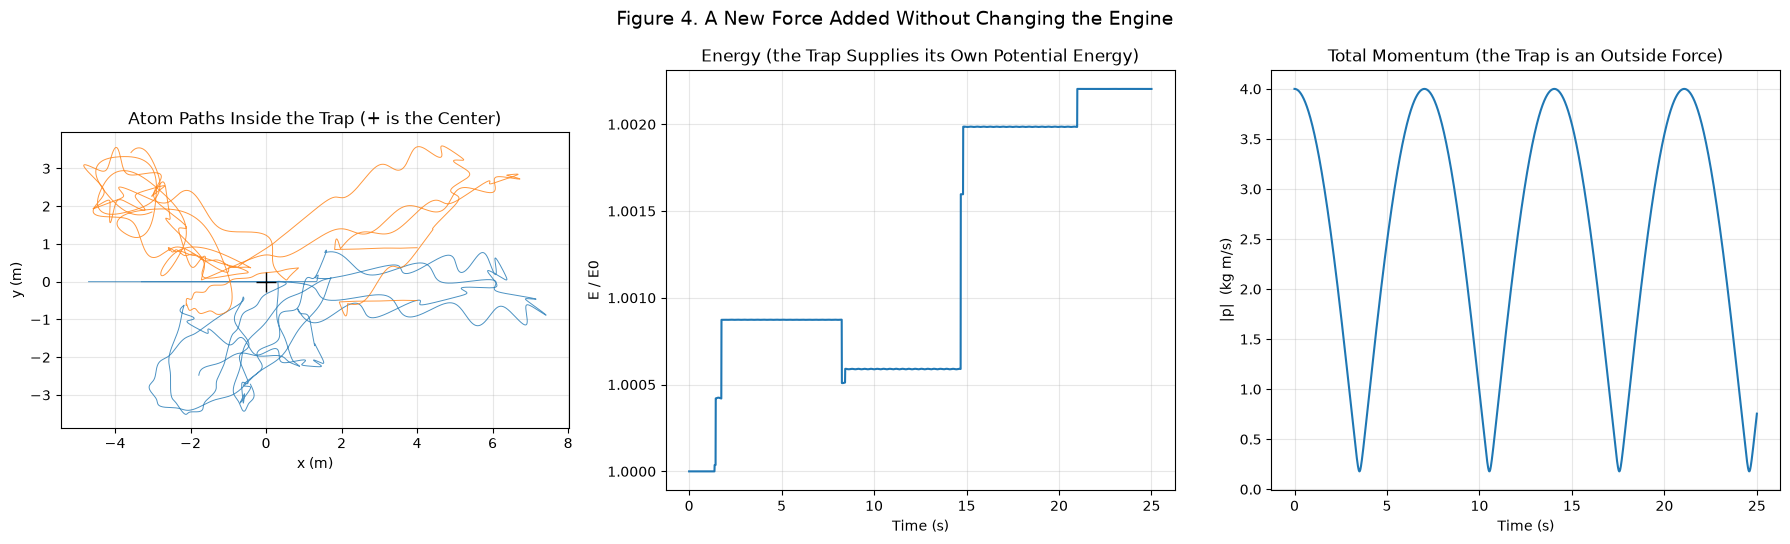

Atom-Atom Collisions in the Trap: 9
Largest |E - E0| / E0: 2.20e-03
Momentum Range: 0.18 to 4.00 kg m/s


In [27]:
class HarmonicTrap(Force):
    def __init__(self, k, center=(0.0, 0.0)):
        self.k = k
        self.center = np.array(center, dtype=float)

    def apply(self, world):
        for b in world.bodies:
            if not b.fixed:
                b.force += -self.k * (b.r - self.center)

    def potential_energy(self, world):
        return sum(0.5 * self.k * np.dot(b.r - self.center, b.r - self.center)
                   for b in world.bodies if not b.fixed)

world_trap = build_scene()
world_trap.add_force(HarmonicTrap(0.2))
data_trap = world_trap.run(dt, t_end=25.0, record_every=20)

tt = data_trap['t']
fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))

for name in names:
    ax[0].plot(data_trap[name + '.x'], data_trap[name + '.y'], lw=0.7, color=colors[name[0]], alpha=0.8)
ax[0].plot(0, 0, 'k+', markersize=14)
ax[0].set_title('Atom Paths Inside the Trap (+ is the Center)')
ax[0].set_xlabel('x (m)')
ax[0].set_ylabel('y (m)')
ax[0].set_aspect('equal')

ax[1].plot(tt, data_trap['E'] / data_trap['E'][0])
ax[1].set_title('Energy (the Trap Supplies its Own Potential Energy)')
ax[1].set_xlabel('Time (s)')
ax[1].set_ylabel('E / E0')

ax[2].plot(tt, np.hypot(data_trap['px'], data_trap['py']))
ax[2].set_title('Total Momentum (the Trap is an Outside Force)')
ax[2].set_xlabel('Time (s)')
ax[2].set_ylabel('|p|  (kg m/s)')

for a in ax:
    a.grid(alpha=0.3)

fig.suptitle("Figure 4. A New Force Added Without Changing the Engine", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig4_new_force.png", dpi=110)
plt.show()

print(f"Atom-Atom Collisions in the Trap: {int(data_trap['collisions'][-1])}")
print(f"Largest |E - E0| / E0: {np.max(np.abs(data_trap['E'] - data_trap['E'][0])) / data_trap['E'][0]:.2e}")
print(f"Momentum Range: {np.hypot(data_trap['px'], data_trap['py']).min():.2f} to {np.hypot(data_trap['px'], data_trap['py']).max():.2f} kg m/s")

The trap is 11 lines of code and one add_force call. With it, the molecules swing back through the center and collide again and again, and the whole group sloshes back and forth. Energy stays conserved to about 0.2 percent of E0, because the trap reports its potential energy. Momentum is no longer conserved, and that is correct, since the trap is an outside force. The engine did not need to know anything about the trap.

## Summary

- The scene has 4 interacting bodies, 3 force types (Spring, NewtonGravity, and Drag in run C), and atom-atom collisions. A fourth force, HarmonicTrap, was added in the last section.
- All stepping, recording, and energy bookkeeping was done by the engine. The notebook only builds the scene and plots.
- The conservation laws behave correctly in all three runs, so the engine is trustworthy for a scene like this.

**Limits worth knowing**

- Collisions are frictionless. They change velocities but never spin.
- After a collision, overlapping atoms are pushed apart. This makes a small error in energy and angular momentum.
- The weak attraction is NewtonGravity with a small G. It stands in for an intermolecular force and is not a real molecular potential.
- Collision checking tests every pair of atoms.